In [ ]:

# ==================================================
# PROYECTO: OPTIMIZACIÓN DE CARGAS EN RUTA Y
# MÉTRICAS DE DESEMPEÑO
# ==================================================

# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

# Configuración general
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

sns.set_theme(style="whitegrid")

print("Entorno de trabajo configurado correctamente.")


Entorno de trabajo configurado correctamente.


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving datos_logistica.zip.zip to datos_logistica.zip.zip


In [ ]:

# Descomprimir el archivo ZIP

ruta_zip = '/content/datos_logistica.zip.zip'
carpeta_datos = '/content/logistics_data'

with zipfile.ZipFile(ruta_zip, 'r') as archivo_zip:
    archivo_zip.extractall(carpeta_datos)

# Cargar automáticamente los archivos CSV
tablas = {}

for raiz, carpetas, archivos in os.walk(carpeta_datos):
    for archivo in archivos:
        if archivo.endswith('.csv'):
            nombre = archivo.replace('.csv', '')
            ruta = os.path.join(raiz, archivo)
            tablas[nombre] = pd.read_csv(ruta)

# Verificar archivos cargados
print("TABLAS CARGADAS:", len(tablas))
print("\nREGISTROS Y COLUMNAS:")

for nombre, df in tablas.items():
    print(f"{nombre}: {df.shape[0]} registros | {df.shape[1]} columnas")


TABLAS CARGADAS: 6

REGISTROS Y COLUMNAS:
routes: 58 registros | 9 columnas
trips: 85410 registros | 12 columnas
loads: 85410 registros | 12 columnas
truck_utilization_metrics: 3312 registros | 10 columnas
trucks: 120 registros | 11 columnas
delivery_events: 170820 registros | 11 columnas


In [ ]:

# Revisar estructura de las tablas del Factor 1

print("=== TRUCK UTILIZATION METRICS ===")
display(tablas['truck_utilization_metrics'].head())

print("\n=== TRUCKS ===")
display(tablas['trucks'].head())

print("\n=== COLUMNAS DISPONIBLES ===")
print("Utilization metrics:",
      tablas['truck_utilization_metrics'].columns.tolist())

print("Trucks:",
      tablas['trucks'].columns.tolist())


=== TRUCK UTILIZATION METRICS ===


,truck_id,month,trips_completed,total_miles,total_revenue,average_mpg,maintenance_events,maintenance_cost,downtime_hours,utilization_rate
0,TRK00001,2022-01-01,22,39269,84792.020,6.780,2,4380.980,63.100,0.710
1,TRK00001,2022-02-01,27,40787,88809.050,6.230,0,0.000,0.000,0.964
2,TRK00001,2022-03-01,34,57422,120453.710,6.490,0,0.000,0.000,1.097
3,TRK00001,2022-04-01,20,34428,73531.280,6.500,2,3548.150,71.800,0.667
4,TRK00001,2022-05-01,16,20851,40791.530,6.380,1,1969.420,43.900,0.516



=== TRUCKS ===


,truck_id,unit_number,make,model_year,vin,acquisition_date,acquisition_mileage,fuel_type,tank_capacity_gallons,status,home_terminal
0,TRK00001,3463,Peterbilt,2016,1VV205190335317039,2017-04-27,18814,Diesel,200,Active,Omaha
1,TRK00002,6461,Kenworth,2015,1NV753749606229960,2018-10-04,26795,Diesel,150,Active,Seattle
2,TRK00003,2335,Peterbilt,2018,1NT803101860493229,2020-09-17,11795,Diesel,150,Maintenance,Atlanta
3,TRK00004,3317,Freightliner,2015,1VV131945381692351,2017-06-17,8875,Diesel,200,Active,Salt Lake City
4,TRK00005,6731,Freightliner,2016,1FT822215709701985,2021-10-08,42042,Diesel,250,Maintenance,Miami



=== COLUMNAS DISPONIBLES ===
Utilization metrics: ['truck_id', 'month', 'trips_completed', 'total_miles', 'total_revenue', 'average_mpg', 'maintenance_events', 'maintenance_cost', 'downtime_hours', 'utilization_rate']
Trucks: ['truck_id', 'unit_number', 'make', 'model_year', 'vin', 'acquisition_date', 'acquisition_mileage', 'fuel_type', 'tank_capacity_gallons', 'status', 'home_terminal']


In [ ]:

# ==========================================
# DIAGNÓSTICO INICIAL - FACTOR 1
# ==========================================

df = tablas['truck_utilization_metrics']

# 1. Tipos de datos
print("TIPOS DE DATOS")
display(df.dtypes)

# 2. Valores faltantes
print("\nVALORES FALTANTES")
display(df.isnull().sum())

# 3. Registros duplicados
print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

# 4. Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df[['trips_completed',
            'total_miles',
            'downtime_hours',
            'utilization_rate']].describe().T)

# 5. Valores únicos de vehículos
print("\nCANTIDAD DE CAMIONES")
print(df['truck_id'].nunique())


TIPOS DE DATOS


,0
truck_id,object
month,object
trips_completed,int64
total_miles,int64
total_revenue,float64
average_mpg,float64
maintenance_events,int64
maintenance_cost,float64
downtime_hours,float64
utilization_rate,float64



VALORES FALTANTES


,0
truck_id,0
month,0
trips_completed,0
total_miles,0
total_revenue,0
average_mpg,0
maintenance_events,0
maintenance_cost,0
downtime_hours,0
utilization_rate,0



REGISTROS DUPLICADOS
0

ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max
trips_completed,3312.000,25.283,5.098,11.000,22.000,25.000,29.000,46.000
total_miles,3312.000,36152.230,8213.092,12680.000,30443.500,35758.000,41550.750,71177.000
downtime_hours,3312.000,16.550,22.997,0.000,0.000,0.000,30.200,152.200
utilization_rate,3312.000,0.830,0.166,0.387,0.710,0.833,0.935,1.484



CANTIDAD DE CAMIONES
92


In [ ]:

# ==========================================
# VALIDACIÓN DE UTILIZACIÓN DE FLOTA
# ==========================================

df_util = tablas['truck_utilization_metrics']
df_trucks = tablas['trucks']

# 1. Comparar camiones
ids_metricas = set(df_util['truck_id'].unique())
ids_camiones = set(df_trucks['truck_id'].unique())

print("Camiones en métricas:", len(ids_metricas))
print("Camiones en inventario:", len(ids_camiones))
print("Camiones sin métricas:", len(ids_camiones - ids_metricas))

# 2. Revisar utilización superior al 100%
print("\nRegistros con utilización superior al 100%:")
display(
    df_util[df_util['utilization_rate'] > 1]
    [['truck_id', 'month', 'utilization_rate']]
    .head(10)
)

# 3. Verificar registros por camión y mes
print("\nDuplicados por camión y mes:")
print(df_util.duplicated(subset=['truck_id', 'month']).sum())

# 4. Revisar distribución de utilización
print("\nFrecuencia de valores:")
print(df_util['utilization_rate'].describe())


Camiones en métricas: 92
Camiones en inventario: 120
Camiones sin métricas: 28

Registros con utilización superior al 100%:


,truck_id,month,utilization_rate
2,TRK00001,2022-03-01,1.097
5,TRK00001,2022-06-01,1.033
9,TRK00001,2022-10-01,1.194
17,TRK00001,2023-06-01,1.033
21,TRK00001,2023-10-01,1.161
26,TRK00001,2024-03-01,1.097
33,TRK00001,2024-10-01,1.194
36,TRK00002,2022-01-01,1.355
43,TRK00002,2022-08-01,1.161
48,TRK00002,2023-01-01,1.097



Duplicados por camión y mes:
0

Frecuencia de valores:
count   3312.000
mean       0.830
std        0.166
min        0.387
25%        0.710
50%        0.833
75%        0.935
max        1.484
Name: utilization_rate, dtype: float64


In [ ]:

# ==========================================
# VALIDACIÓN FINAL DEL FACTOR 1
# ==========================================

df_util = tablas['truck_utilization_metrics']
df_trucks = tablas['trucks']

# 1. Periodo analizado
df_util['month'] = pd.to_datetime(df_util['month'])

print("PERIODO ANALIZADO")
print("Desde:", df_util['month'].min())
print("Hasta:", df_util['month'].max())
print("Meses registrados:", df_util['month'].nunique())

# 2. Estado de los camiones sin métricas
ids_sin_metricas = set(df_trucks['truck_id']) - set(df_util['truck_id'])

print("\nESTADO DE LOS CAMIONES SIN MÉTRICAS")
display(
    df_trucks[df_trucks['truck_id'].isin(ids_sin_metricas)]
    ['status'].value_counts()
)

# 3. Distribución de utilización
print("\nUTILIZACIÓN SUPERIOR AL 100%")

cantidad = (df_util['utilization_rate'] > 1).sum()
porcentaje = cantidad / len(df_util) * 100

print("Registros:", cantidad)
print(f"Porcentaje: {porcentaje:.2f}%")

# 4. Moda de utilización
print("\nMODA DE UTILIZACIÓN")
print(df_util['utilization_rate'].mode().tolist())


PERIODO ANALIZADO
Desde: 2022-01-01 00:00:00
Hasta: 2024-12-01 00:00:00
Meses registrados: 36

ESTADO DE LOS CAMIONES SIN MÉTRICAS


,count
status,
Maintenance,15
Inactive,13



UTILIZACIÓN SUPERIOR AL 100%
Registros: 436
Porcentaje: 13.16%

MODA DE UTILIZACIÓN
[0.839]


In [ ]:

# FACTOR 1: UTILIZACION OPERATIVA DE LA FLOTA

df_factor1 = tablas['truck_utilization_metrics'].copy()

variables = [
    'utilization_rate',
    'trips_completed',
    'downtime_hours'
]

estadisticas_factor1 = pd.DataFrame({
    'Media': df_factor1[variables].mean(),
    'Moda': df_factor1[variables].mode().iloc[0],
    'Desviacion_estandar': df_factor1[variables].std(),
    'Minimo': df_factor1[variables].min(),
    'Maximo': df_factor1[variables].max()
})

display(estadisticas_factor1.round(3))


,Media,Moda,Desviacion_estandar,Minimo,Maximo
utilization_rate,0.830,0.839,0.166,0.387,1.484
trips_completed,25.283,25.000,5.098,11.000,46.000
downtime_hours,16.550,0.000,22.997,0.000,152.200


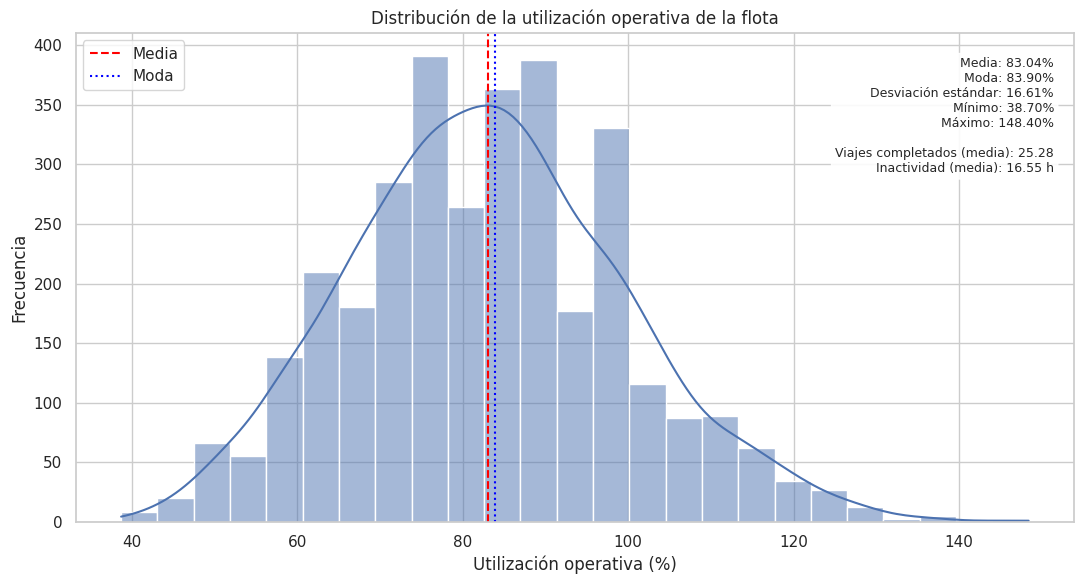

In [ ]:

# GRAFICO 1: UTILIZACION OPERATIVA DE LA FLOTA

fig, ax = plt.subplots(figsize=(11, 6))

sns.histplot(
    data=df_factor1,
    x=df_factor1['utilization_rate'] * 100,
    bins=25,
    kde=True,
    ax=ax
)

# Media y moda
media = df_factor1['utilization_rate'].mean() * 100
moda = df_factor1['utilization_rate'].mode()[0] * 100

ax.axvline(media, color='red', linestyle='--', label='Media')
ax.axvline(moda, color='blue', linestyle=':', label='Moda')

# Estadisticas descriptivas
resumen = (
    f"Media: {media:.2f}%\n"
    f"Moda: {moda:.2f}%\n"
    f"Desviación estándar: {df_factor1['utilization_rate'].std()*100:.2f}%\n"
    f"Mínimo: {df_factor1['utilization_rate'].min()*100:.2f}%\n"
    f"Máximo: {df_factor1['utilization_rate'].max()*100:.2f}%\n\n"
    f"Viajes completados (media): {df_factor1['trips_completed'].mean():.2f}\n"
    f"Inactividad (media): {df_factor1['downtime_hours'].mean():.2f} h"
)

ax.text(
    0.98, 0.95, resumen,
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=9,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.9)
)

ax.set_title('Distribución de la utilización operativa de la flota')
ax.set_xlabel('Utilización operativa (%)')
ax.set_ylabel('Frecuencia')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [ ]:

# FACTOR 2: DESVIACION DEL TIEMPO DE TRANSITO

df_trips = tablas['trips'].copy()
df_routes = tablas['routes'].copy()
df_events = tablas['delivery_events'].copy()

# Revisar columnas disponibles
print("TRIPS")
print(df_trips.columns.tolist())

print("\nROUTES")
print(df_routes.columns.tolist())

print("\nDELIVERY EVENTS")
print(df_events.columns.tolist())


TRIPS
['trip_id', 'load_id', 'driver_id', 'truck_id', 'trailer_id', 'dispatch_date', 'actual_distance_miles', 'actual_duration_hours', 'fuel_gallons_used', 'average_mpg', 'idle_time_hours', 'trip_status']

ROUTES
['route_id', 'origin_city', 'origin_state', 'destination_city', 'destination_state', 'typical_distance_miles', 'base_rate_per_mile', 'fuel_surcharge_rate', 'typical_transit_days']

DELIVERY EVENTS
['event_id', 'load_id', 'trip_id', 'event_type', 'facility_id', 'scheduled_datetime', 'actual_datetime', 'detention_minutes', 'on_time_flag', 'location_city', 'location_state']


In [ ]:
#Hay un detalle importante: trips no contiene directamente route_id, pero podemos obtenerlo relacionando trips con loads mediante load_id.
# FACTOR 2: REVISION DE EVENTOS Y TIEMPOS

# Revisar tipos de eventos
print("TIPOS DE EVENTOS:")
display(df_events['event_type'].value_counts())

# Revisar valores de puntualidad
print("\nVALORES DE ON_TIME_FLAG:")
display(df_events['on_time_flag'].value_counts(dropna=False))

# Mostrar registros de entrega
print("\nMUESTRA DE EVENTOS:")
display(df_events[
    ['trip_id', 'event_type', 'scheduled_datetime',
     'actual_datetime', 'on_time_flag']
].head(10))

# Revisar datos faltantes
print("\nDATOS FALTANTES:")
display(df_events[
    ['trip_id', 'event_type', 'scheduled_datetime',
     'actual_datetime', 'on_time_flag']
].isnull().sum())


TIPOS DE EVENTOS:


,count
event_type,
Pickup,85410
Delivery,85410



VALORES DE ON_TIME_FLAG:


,count
on_time_flag,
True,95095
False,75725



MUESTRA DE EVENTOS:


,trip_id,event_type,scheduled_datetime,actual_datetime,on_time_flag
0,TRIP00000001,Pickup,2022-01-01 18:00:00.000000,2022-01-01 20:58:55.918185,False
1,TRIP00000001,Delivery,2022-01-02 23:10:55.918185,2022-01-02 21:30:22.142060,True
2,TRIP00000002,Pickup,2022-01-01 18:00:00.000000,2022-01-01 17:37:26.608430,True
3,TRIP00000002,Delivery,2022-01-02 02:13:26.608430,2022-01-02 05:55:46.238257,False
4,TRIP00000003,Pickup,2022-01-01 08:00:00.000000,2022-01-01 07:28:02.169634,True
5,TRIP00000003,Delivery,2022-01-03 04:28:02.169634,2022-01-03 03:05:02.833256,True
6,TRIP00000004,Pickup,2022-01-01 17:00:00.000000,2022-01-01 19:32:56.020030,False
7,TRIP00000004,Delivery,2022-01-02 06:38:56.020030,2022-01-02 08:41:06.714927,False
8,TRIP00000005,Pickup,2022-01-01 08:00:00.000000,2022-01-01 11:51:35.544202,False
9,TRIP00000005,Delivery,2022-01-02 22:51:35.544202,2022-01-02 22:23:50.185284,True



DATOS FALTANTES:


,0
trip_id,0
event_type,0
scheduled_datetime,0
actual_datetime,0
on_time_flag,0


In [ ]:

# FACTOR 2: DESVIACION DEL TIEMPO DE TRANSITO

# Filtrar exclusivamente eventos de entrega
df_delivery = df_events[
    df_events['event_type'] == 'Delivery'
].copy()

# Convertir fechas
df_delivery['scheduled_datetime'] = pd.to_datetime(
    df_delivery['scheduled_datetime']
)

df_delivery['actual_datetime'] = pd.to_datetime(
    df_delivery['actual_datetime']
)

# Calcular desviacion en horas
df_delivery['delay_hours'] = (
    df_delivery['actual_datetime'] -
    df_delivery['scheduled_datetime']
).dt.total_seconds() / 3600

# Estadisticas descriptivas
print("ESTADISTICAS DE DESVIACION DEL TIEMPO DE ENTREGA")

display(
    df_delivery['delay_hours'].describe().to_frame().T
)

# Tasa de entregas a tiempo
otd = df_delivery['on_time_flag'].mean() * 100

print(f"\nTasa de entregas a tiempo (OTD): {otd:.2f}%")

# Verificar registros
print("\nTotal de entregas:", len(df_delivery))
print("Entregas puntuales:", df_delivery['on_time_flag'].sum())
print("Entregas no puntuales:", (~df_delivery['on_time_flag']).sum())


ESTADISTICAS DE DESVIACION DEL TIEMPO DE ENTREGA


,count,mean,std,min,25%,50%,75%,max
delay_hours,85410.000,1.505,2.598,-3.000,-0.747,1.507,3.756,6.000



Tasa de entregas a tiempo (OTD): 44.61%

Total de entregas: 85410
Entregas puntuales: 38102
Entregas no puntuales: 47308


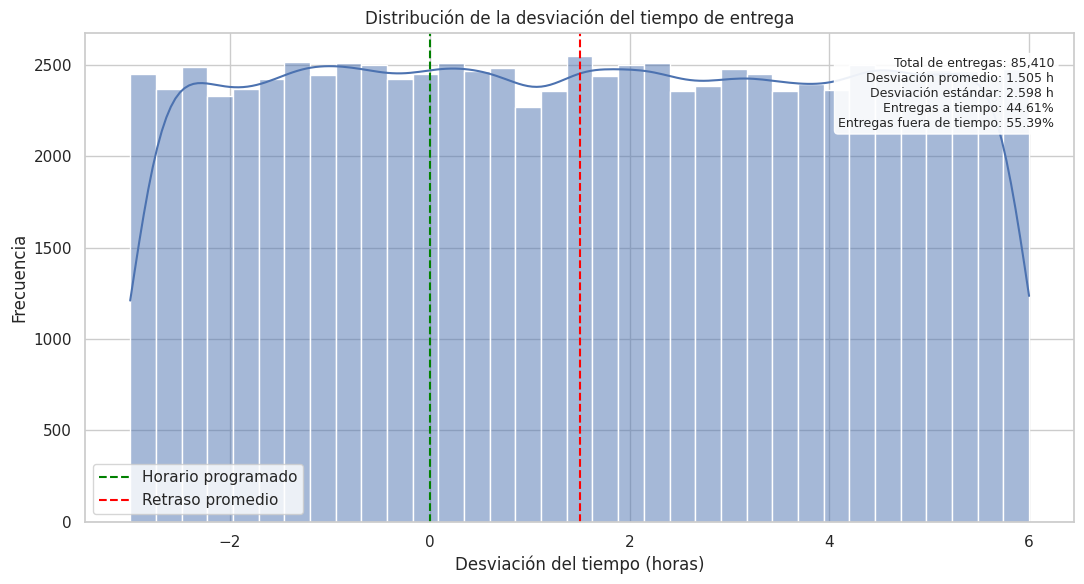

In [ ]:

# GRAFICO 2: DESVIACION DEL TIEMPO DE ENTREGA

fig, ax = plt.subplots(figsize=(11, 6))

sns.histplot(
    data=df_delivery,
    x='delay_hours',
    bins=35,
    kde=True,
    ax=ax
)

ax.axvline(0, color='green', linestyle='--',
           label='Horario programado')

ax.axvline(df_delivery['delay_hours'].mean(),
           color='red', linestyle='--',
           label='Retraso promedio')

# Indicadores del gráfico
otd = df_delivery['on_time_flag'].mean() * 100
no_otd = 100 - otd

resumen = (
    f"Total de entregas: {len(df_delivery):,}\n"
    f"Desviación promedio: {df_delivery['delay_hours'].mean():.3f} h\n"
    f"Desviación estándar: {df_delivery['delay_hours'].std():.3f} h\n"
    f"Entregas a tiempo: {otd:.2f}%\n"
    f"Entregas fuera de tiempo: {no_otd:.2f}%"
)

ax.text(
    0.98, 0.95, resumen,
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=9,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.9)
)

ax.set_title('Distribución de la desviación del tiempo de entrega')
ax.set_xlabel('Desviación del tiempo (horas)')
ax.set_ylabel('Frecuencia')
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# FACTOR 3: RENDIMIENTO DE COMBUSTIBLE
# ==========================================

df_factor3 = tablas['trips'].copy()

variables_f3 = [
    'average_mpg',
    'actual_distance_miles',
    'fuel_gallons_used'
]

# Estadisticas descriptivas
estadisticas_factor3 = pd.DataFrame({
    'Media': df_factor3[variables_f3].mean(),
    'Moda': df_factor3[variables_f3].mode().iloc[0],
    'Desviacion_estandar': df_factor3[variables_f3].std(),
    'Minimo': df_factor3[variables_f3].min(),
    'Maximo': df_factor3[variables_f3].max()
})

print("ESTADISTICAS DESCRIPTIVAS - FACTOR 3")

display(estadisticas_factor3.round(3))

# Revision de datos faltantes
print("\nVALORES FALTANTES:")
display(df_factor3[variables_f3].isnull().sum())

# Revision de registros duplicados
print("\nREGISTROS DUPLICADOS:")
print(df_factor3.duplicated().sum())


ESTADISTICAS DESCRIPTIVAS - FACTOR 3


,Media,Moda,Desviacion_estandar,Minimo,Maximo
average_mpg,6.501,6.720,0.578,5.500,7.500
actual_distance_miles,1430.268,91.000,801.932,90.000,3391.000
fuel_gallons_used,221.827,13.000,126.559,12.000,611.900



VALORES FALTANTES:


,0
average_mpg,0
actual_distance_miles,0
fuel_gallons_used,0



REGISTROS DUPLICADOS:
0


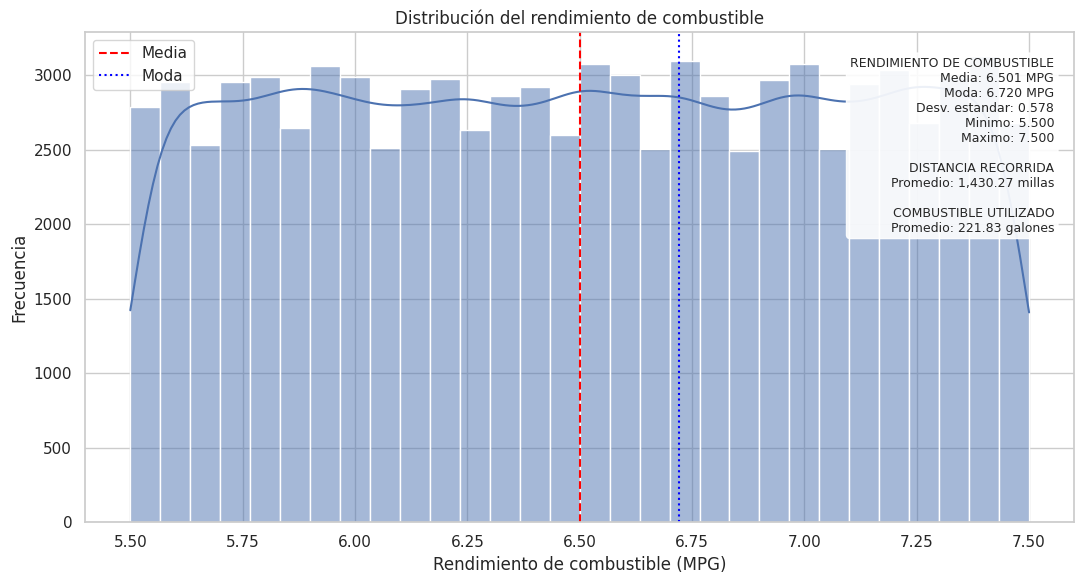

In [ ]:

# ==========================================
# GRAFICO 3: RENDIMIENTO DE COMBUSTIBLE
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

# Distribucion del rendimiento MPG
sns.histplot(
    data=df_factor3,
    x='average_mpg',
    bins=30,
    kde=True,
    ax=ax
)

# Media y moda
media = df_factor3['average_mpg'].mean()
moda = df_factor3['average_mpg'].mode()[0]

ax.axvline(media, color='red', linestyle='--', label='Media')
ax.axvline(moda, color='blue', linestyle=':', label='Moda')

# Resumen estadistico
resumen = (
    f"RENDIMIENTO DE COMBUSTIBLE\n"
    f"Media: {media:.3f} MPG\n"
    f"Moda: {moda:.3f} MPG\n"
    f"Desv. estandar: {df_factor3['average_mpg'].std():.3f}\n"
    f"Minimo: {df_factor3['average_mpg'].min():.3f}\n"
    f"Maximo: {df_factor3['average_mpg'].max():.3f}\n\n"
    f"DISTANCIA RECORRIDA\n"
    f"Promedio: {df_factor3['actual_distance_miles'].mean():,.2f} millas\n\n"
    f"COMBUSTIBLE UTILIZADO\n"
    f"Promedio: {df_factor3['fuel_gallons_used'].mean():,.2f} galones"
)

ax.text(
    0.98, 0.95, resumen,
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.9)
)

ax.set_title('Distribución del rendimiento de combustible')
ax.set_xlabel('Rendimiento de combustible (MPG)')
ax.set_ylabel('Frecuencia')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [ ]:
!pip install -q xgboost

In [ ]:
print("TRIPS:")
print(tablas["trips"].columns.tolist())

print("\nROUTES:")
print(tablas["routes"].columns.tolist())

print("\nLOADS:")
print(tablas["loads"].columns.tolist())

TRIPS:
['trip_id', 'load_id', 'driver_id', 'truck_id', 'trailer_id', 'dispatch_date', 'actual_distance_miles', 'actual_duration_hours', 'fuel_gallons_used', 'average_mpg', 'idle_time_hours', 'trip_status']

ROUTES:
['route_id', 'origin_city', 'origin_state', 'destination_city', 'destination_state', 'typical_distance_miles', 'base_rate_per_mile', 'fuel_surcharge_rate', 'typical_transit_days']

LOADS:
['load_id', 'customer_id', 'route_id', 'load_date', 'load_type', 'weight_lbs', 'pieces', 'revenue', 'fuel_surcharge', 'accessorial_charges', 'load_status', 'booking_type']


In [ ]:

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Integrar las tablas
df_model3 = tablas["trips"].merge(
    tablas["loads"][["load_id", "weight_lbs", "pieces",
                     "load_type", "booking_type", "route_id"]],
    on="load_id", how="left"
)

df_model3 = df_model3.merge(
    tablas["routes"][["route_id", "origin_city", "destination_city",
                      "typical_distance_miles", "typical_transit_days"]],
    on="route_id", how="left"
)

# 2. Crear variables temporales
df_model3["dispatch_date"] = pd.to_datetime(
    df_model3["dispatch_date"], errors="coerce"
)

df_model3["dispatch_month"] = df_model3["dispatch_date"].dt.month
df_model3["dispatch_day"] = df_model3["dispatch_date"].dt.dayofweek

# 3. Definir variables predictoras y objetivo
variables = [
    "typical_distance_miles",
    "typical_transit_days",
    "weight_lbs",
    "pieces",
    "load_type",
    "booking_type",
    "route_id",
    "origin_city",
    "destination_city",
    "dispatch_month",
    "dispatch_day"
]

X = df_model3[variables].copy()
y = df_model3["actual_duration_hours"]

# Eliminar registros sin variable objetivo
datos = pd.concat([X, y.rename("actual_duration_hours")], axis=1)
datos = datos.dropna(subset=["actual_duration_hours"])

X = datos[variables]
y = datos["actual_duration_hours"]

# 4. Separar entrenamiento y prueba
X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 5. Preprocesamiento
categoricas = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categoricas += ["route_id"] if "route_id" not in categoricas else []

numericas = [c for c in X.columns if c not in categoricas]

preprocesamiento3 = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categoricas)
])

# 6. Configurar XGBoost
modelo3 = Pipeline([
    ("preprocesamiento", preprocesamiento3),
    ("regresor", XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# 7. Entrenar y predecir
modelo3.fit(X_train3, y_train3)
predicciones3 = modelo3.predict(X_test3)

# 8. Evaluar
r2_3 = r2_score(y_test3, predicciones3)
mae_3 = mean_absolute_error(y_test3, predicciones3)
rmse_3 = np.sqrt(mean_squared_error(y_test3, predicciones3))

print("RESULTADOS XGBOOST - MODELO 3")
print(f"R²:   {r2_3:.4f} ({r2_3*100:.2f}%)")
print(f"MAE:  {mae_3:.4f} horas")
print(f"RMSE: {rmse_3:.4f} horas")
print(f"Registros: {len(datos)}")


RESULTADOS XGBOOST - MODELO 3
R²:   0.9733 (97.33%)
MAE:  1.7130 horas
RMSE: 2.3182 horas
Registros: 85410


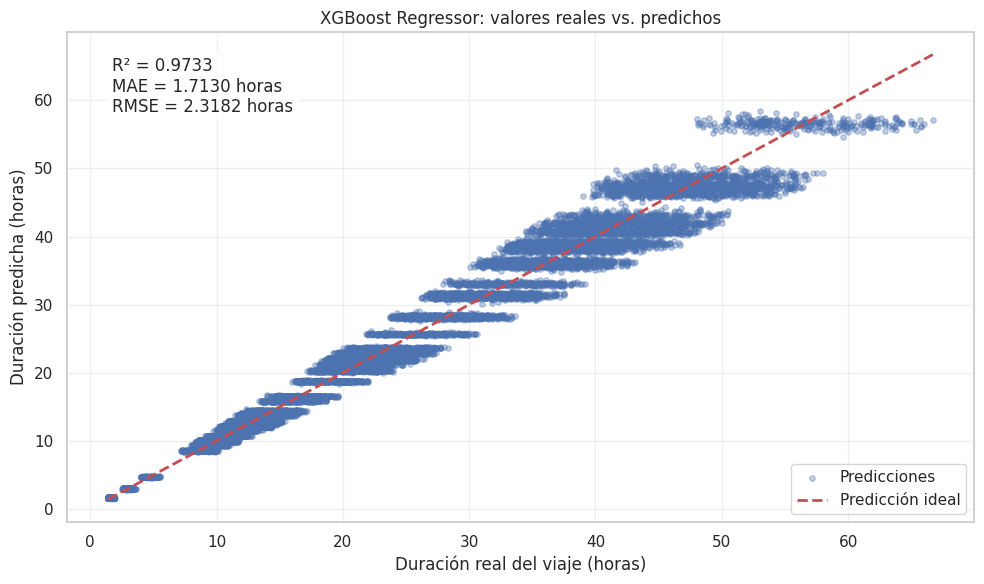

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

# Valores reales y predichos
y_real = np.array(y_test3)
y_pred = np.array(predicciones3)

# Gráfico
plt.figure(figsize=(10, 6))

plt.scatter(
    y_real, y_pred,
    alpha=0.35,
    s=15,
    label="Predicciones"
)

# Línea de predicción perfecta
limite_min = min(y_real.min(), y_pred.min())
limite_max = max(y_real.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    linewidth=2,
    label="Predicción ideal"
)

plt.xlabel("Duración real del viaje (horas)")
plt.ylabel("Duración predicha (horas)")
plt.title("XGBoost Regressor: valores reales vs. predichos")

plt.text(
    0.05, 0.95,
    f"R² = {r2_score(y_real, y_pred):.4f}\n"
    f"MAE = {mae_3:.4f} horas\n"
    f"RMSE = {rmse_3:.4f} horas",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


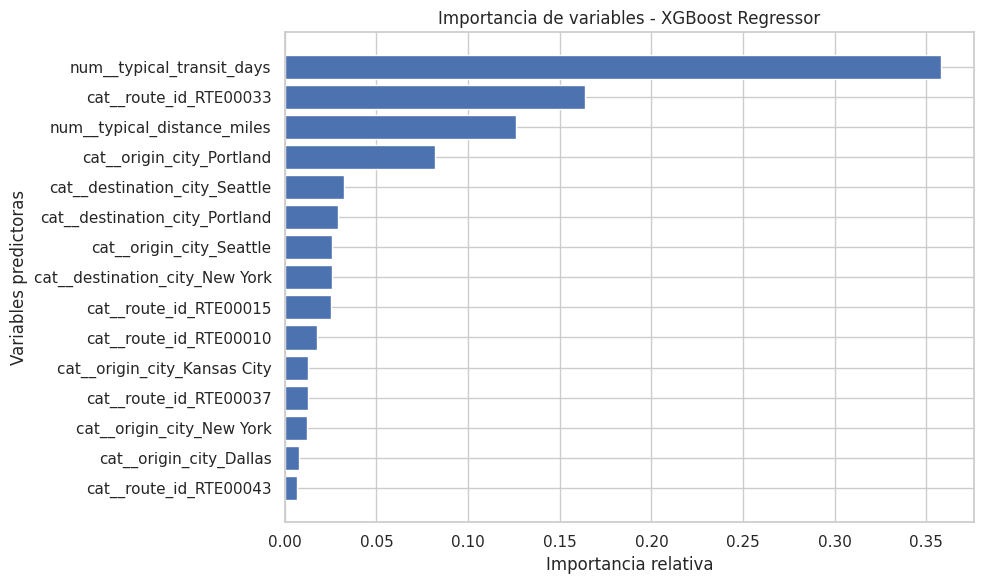

,Variable,Importancia (%)
1,num__typical_transit_days,35.810
43,cat__route_id_RTE00033,16.400
0,num__typical_distance_miles,12.610
85,cat__origin_city_Portland,8.210
105,cat__destination_city_Seattle,3.210
104,cat__destination_city_Portland,2.880
86,cat__origin_city_Seattle,2.560
102,cat__destination_city_New York,2.550
25,cat__route_id_RTE00015,2.530
20,cat__route_id_RTE00010,1.740


In [ ]:

# Obtener nombres de las variables después del preprocesamiento
nombres_variables = modelo3.named_steps[
    "preprocesamiento"
].get_feature_names_out()

# Obtener importancia de cada variable
importancias = modelo3.named_steps[
    "regresor"
].feature_importances_

# Crear tabla ordenada
df_importancia = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": importancias
})

df_importancia = df_importancia.sort_values(
    by="Importancia", ascending=False
).head(15)

# Gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    df_importancia["Variable"][::-1],
    df_importancia["Importancia"][::-1]
)

plt.xlabel("Importancia relativa")
plt.ylabel("Variables predictoras")
plt.title("Importancia de variables - XGBoost Regressor")

plt.tight_layout()
plt.show()

# Mostrar porcentajes
df_importancia["Importancia (%)"] = (
    df_importancia["Importancia"] * 100
).round(2)

display(df_importancia[["Variable", "Importancia (%)"]])

